                 time   pressure
0 2026-01-01 00:00:00  50.248357
1 2026-01-01 00:01:00  49.930868
2 2026-01-01 00:02:00  50.323844
3 2026-01-01 00:03:00  50.761515
4 2026-01-01 00:04:00  49.882923
                                time     pressure
count                           1000  1000.000000
mean   2026-01-01 08:19:29.999999744    50.009666
min              2026-01-01 00:00:00    41.435147
25%              2026-01-01 04:09:45    49.673983
50%              2026-01-01 08:19:30    50.012650
75%              2026-01-01 12:29:15    50.326067
max              2026-01-01 16:39:00    58.410241
std                              NaN     0.936269


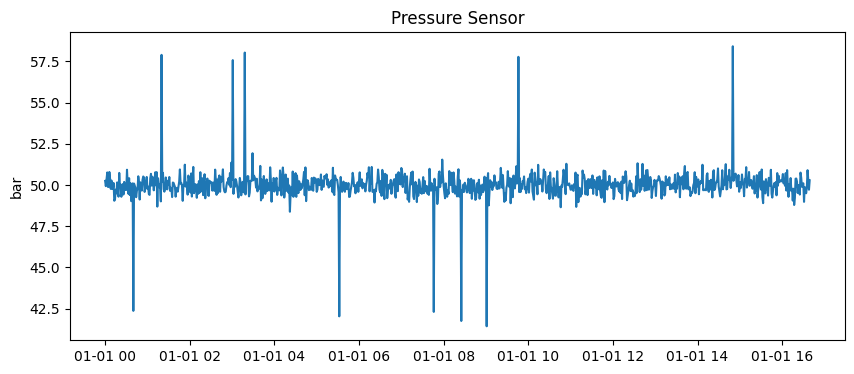

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n = 1000
time = pd.date_range("2026-01-01", periods=n, freq="min")
pressure = 50 + np.random.normal(0, 0.5, n)

# نضيف 10 قراءات شاذة (مثل خلل بالحساس)
idx = np.random.choice(n, 10, replace=False)
pressure[idx] += np.random.choice([-8, 8], 10)

df = pd.DataFrame({"time": time, "pressure": pressure})
print(df.head())
print(df.describe())

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["pressure"])
plt.title("Pressure Sensor")
plt.ylabel("bar")
plt.show()

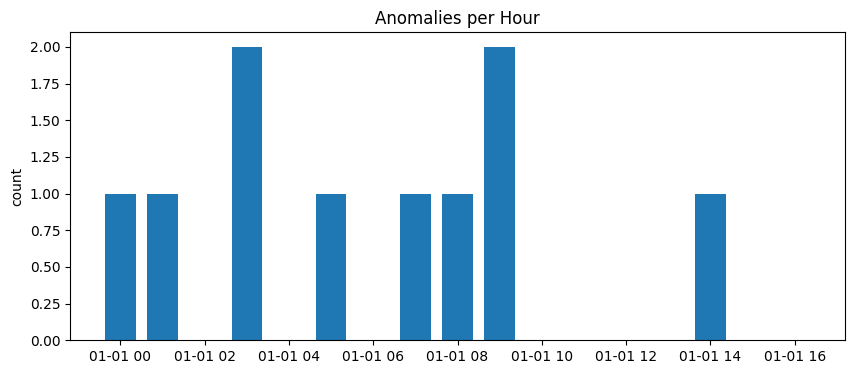

Total anomalies: 10


In [2]:
# نعتبر القراءة شاذة إذا بعيدة أكثر من 3 انحرافات معيارية عن المتوسط
mean = df["pressure"].mean()
std = df["pressure"].std()
df["anomaly"] = (df["pressure"] - mean).abs() > 3 * std

# عدد الشواذ بكل ساعة
per_hour = df.set_index("time")["anomaly"].resample("h").sum()

plt.figure(figsize=(10, 4))
plt.bar(per_hour.index, per_hour.values, width=0.03)
plt.title("Anomalies per Hour")
plt.ylabel("count")
plt.show()

print("Total anomalies:", df["anomaly"].sum())

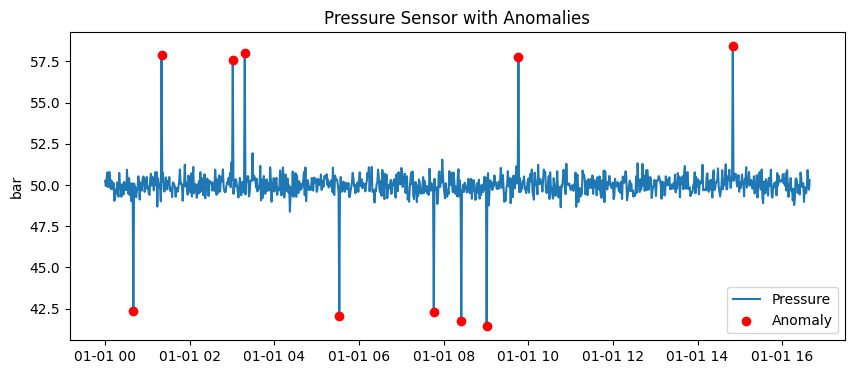

In [3]:
mean = df["pressure"].mean()
std = df["pressure"].std()
df["anomaly"] = (df["pressure"] - mean).abs() > 3 * std

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["pressure"], label="Pressure")
plt.scatter(df[df["anomaly"]]["time"], df[df["anomaly"]]["pressure"],
            color="red", label="Anomaly", zorder=3)
plt.title("Pressure Sensor with Anomalies")
plt.ylabel("bar")
plt.legend()
plt.show()